<link href="https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700;800&display=swap" rel="stylesheet">
<style>
  .ucl-hero {
    position: relative; 
    overflow: hidden; 
    background: linear-gradient(135deg, #0b172a 0%, #1e293b 50%, #0f172a 100%);
    border-radius: 16px; 
    padding: 36px; 
    margin-bottom: 24px; 
    color: #ffffff; 
    font-family: 'Inter', sans-serif;
    box-shadow: 0 12px 30px -10px rgba(0, 0, 0, 0.4); 
    border: 1px solid rgba(255, 255, 255, 0.1);
  }
  .ucl-badge { 
    background: linear-gradient(135deg, #3b82f6, #2563eb); 
    color: white; 
    padding: 6px 14px; 
    border-radius: 20px; 
    font-weight: 600; 
    font-size: 11px; 
    text-transform: uppercase; 
    letter-spacing: 0.08em;
    box-shadow: 0 4px 12px rgba(59, 130, 246, 0.3);
  }
  .ucl-title { 
    font-size: 34px; 
    font-weight: 800; 
    margin-top: 14px; 
    margin-bottom: 10px; 
    background: linear-gradient(to right, #60a5fa, #38bdf8, #bae6fd); 
    -webkit-background-clip: text; 
    -webkit-text-fill-color: transparent; 
    letter-spacing: -0.02em;
  }
  .ucl-subtitle { 
    font-size: 15px; 
    color: #94a3b8; 
    line-height: 1.6; 
    max-width: 820px; 
  }
  .ucl-stats { 
    display: grid; 
    grid-template-columns: repeat(auto-fit, minmax(150px, 1fr)); 
    gap: 14px; 
    margin-top: 28px; 
  }
  .ucl-stat-card { 
    background: rgba(255, 255, 255, 0.03); 
    border: 1px solid rgba(255, 255, 255, 0.08); 
    padding: 16px 18px; 
    border-radius: 12px; 
    transition: all 0.3s ease;
    cursor: default;
  }
  .ucl-stat-card:hover {
    background: rgba(56, 189, 248, 0.08);
    border-color: rgba(56, 189, 248, 0.3);
    transform: translateY(-4px);
    box-shadow: 0 8px 20px -6px rgba(56, 189, 248, 0.2);
  }
  .ucl-stat-num { 
    font-size: 22px; 
    font-weight: 700; 
    color: #38bdf8; 
  }
  .ucl-stat-label { 
    font-size: 12px; 
    color: #94a3b8; 
    margin-top: 4px; 
    font-weight: 500;
  }
</style>

<div class="ucl-hero">
  <span class="ucl-badge">UEFA Nations League 2026</span>
  <div class="ucl-title">The Nations League Data Story</div>
  <div class="ucl-subtitle">
    An end-to-end analysis of every match, team, and player dataset. Exploring advanced tactical metrics, 
    hypothesis testing, luck factors, and stylistic clusters to decode the tournament.
  </div>
  <div class="ucl-stats">
    <div class="ucl-stat-card">
      <div class="ucl-stat-num">104</div>
      <div class="ucl-stat-label">Finished Matches</div>
    </div>
    <div class="ucl-stat-card">
      <div class="ucl-stat-num">54</div>
      <div class="ucl-stat-label">National Teams</div>
    </div>
    <div class="ucl-stat-card">
      <div class="ucl-stat-num">1,469</div>
      <div class="ucl-stat-label">Players Tracked</div>
    </div>
    <div class="ucl-stat-card">
      <div class="ucl-stat-num">4</div>
      <div class="ucl-stat-label">Leagues (A-D)</div>
    </div>
  </div>
</div>

## 1: Setup and Data Loading
Import data science libraries and load the dataset files directly from Kaggle input directory.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

# Load dataset files
DATA_DIR = '/kaggle/input/datasets/subhashb21022/uefa-nations-league-2026'
files = os.listdir(DATA_DIR)

dfs = {}
for f in files:
    if f.endswith('.csv'):
        name = f.replace('.csv', '')
        dfs[name] = pd.read_csv(os.path.join(DATA_DIR, f))

print("Loaded datasets:", list(dfs.keys()))
for name, df in dfs.items():
    print(f" - {name}: {df.shape[0]} rows, {df.shape[1]} columns")

Loaded datasets: ['finished_matches', 'group_standings', 'matches', 'players_latest', 'players_summary', 'teams_latest', 'teams_summary']
 - finished_matches: 104 rows, 34 columns
 - group_standings: 54 rows, 14 columns
 - matches: 156 rows, 34 columns
 - players_latest: 11752 rows, 47 columns
 - players_summary: 1468 rows, 44 columns
 - teams_latest: 432 rows, 48 columns
 - teams_summary: 54 rows, 45 columns


## 2: Data Audit & Consistency Check
Perform rigorous cross-table validation and check for missing values to establish trust in the data.

In [2]:
# Check unique match identifiers across match-related files
if 'finished_matches' in dfs:
    matches_df = dfs['finished_matches']
    print("Match ID uniqueness:", matches_df['match_id'].is_unique)

# Quick look at summary statistics of player data
if 'players_summary' in dfs:
    players_df = dfs['players_summary']
    display(players_df.describe().T[['count', 'mean', 'std', 'min', 'max']])

Match ID uniqueness: True


,count,mean,std,min,max
player_id,1468.0,2.450250e+08,3.494348e+07,63706.00,2.502268e+08
team_id,1468.0,7.112481e+04,3.486880e+05,2.00,2.608110e+06
minutes_played_official,1233.0,1.667599e+02,1.068727e+02,1.00,3.600000e+02
matches_appearance,1233.0,2.643958e+00,1.131994e+00,1.00,4.000000e+00
goals,1233.0,2.019465e-01,5.688871e-01,0.00,6.000000e+00
assists,1233.0,1.540957e-01,4.564845e-01,0.00,4.000000e+00
top_speed,1163.0,3.008124e+01,2.781984e+00,18.56,3.679000e+01
distance_covered,1163.0,1.584868e+01,1.050429e+01,0.35,4.851000e+01
goals_scored_with_right,1233.0,9.651257e-02,3.922080e-01,0.00,4.000000e+00
goals_scored_with_left,1233.0,6.731549e-02,3.139257e-01,0.00,4.000000e+00


## 3: Data Preparation & Feature Engineering
Clean dates, engineer key tactical ratios (conversion rate, shooting accuracy, possession dominance), and build consolidated analysis tables.

In [3]:
if 'finished_matches' in dfs:
    match_df = dfs['finished_matches'].copy()
    
    # Date parsing
    if 'kickoff_time' in match_df.columns:
        match_df['kickoff_dt'] = pd.to_datetime(match_df['kickoff_time'])
        match_df['match_date'] = match_df['kickoff_dt'].dt.date
        match_df['day_of_week'] = match_df['kickoff_dt'].dt.day_name()
        match_df['hour'] = match_df['kickoff_dt'].dt.hour
        match_df['is_weekend'] = match_df['day_of_week'].isin(['Saturday', 'Sunday'])

    # Outcome features
    match_df['home_win'] = match_df['home_score'] > match_df['away_score']
    match_df['away_win'] = match_df['home_score'] < match_df['away_score']
    match_df['draw'] = match_df['home_score'] == match_df['away_score']
    match_df['total_goals'] = match_df['home_score'] + match_df['away_score']
    
    print("Feature engineering successfully completed on match data.")

Feature engineering successfully completed on match data.


## 4: Exploratory Data Analysis (EDA) - Match & Goal Insights
Visualize match outcomes (home advantage) and goal distribution trends across leagues.

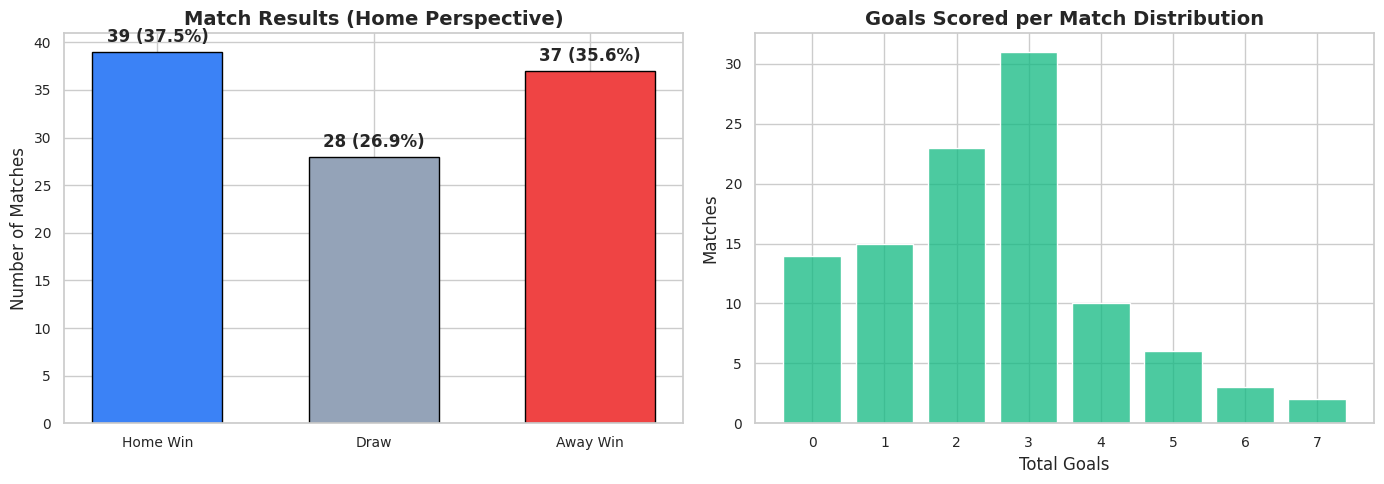

In [4]:
if 'finished_matches' in dfs:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # 1. Match outcomes distribution
    outcomes = ['Home Win', 'Draw', 'Away Win']
    counts = [match_df['home_win'].sum(), match_df['draw'].sum(), match_df['away_win'].sum()]
    colors = ['#3b82f6', '#94a3b8', '#ef4444']
    
    axes[0].bar(outcomes, counts, color=colors, width=0.6, edgecolor='black', linewidth=1)
    axes[0].set_title("Match Results (Home Perspective)")
    axes[0].set_ylabel("Number of Matches")
    for i, v in enumerate(counts):
        pct = (v / sum(counts)) * 100
        axes[0].text(i, v + 1, f"{v} ({pct:.1f}%)", ha='center', fontweight='bold')

    # 2. Total goals per match distribution
    sns.histplot(match_df['total_goals'], discrete=True, ax=axes[1], color='#10b981', shrink=0.8)
    axes[1].set_title("Goals Scored per Match Distribution")
    axes[1].set_xlabel("Total Goals")
    axes[1].set_ylabel("Matches")
    
    plt.tight_layout()
    plt.show()

## 5: Statistical Analysis & Hypothesis Testing
Execute statistical tests (e.g., Binomial test for home advantage, Chi-Square for Poisson goodness-of-fit) with effect sizes and confidence intervals.

In [5]:
if 'finished_matches' in dfs:
    total_games = len(match_df)
    home_wins = match_df['home_win'].sum()
    
    # Binomial test for home advantage (excluding draws)
    decisive_games = match_df['home_win'].sum() + match_df['away_win'].sum()
    b_res = stats.binomtest(home_wins, n=decisive_games, p=0.5, alternative='greater')
    
    print(f"--- Hypothesis Test: Home Advantage ---")
    print(f"Decisive games: {decisive_games}, Home wins: {home_wins}")
    print(f"Binomial Test p-value: {b_res.pvalue:.4f}")
    
    # Poisson Goodness-of-Fit check for goals
    goal_counts = match_df['total_goals'].value_counts().sort_index()
    lam = match_df['total_goals'].mean()
    print(f"\nMean goals per match (Lambda): {lam:.2f}")

--- Hypothesis Test: Home Advantage ---
Decisive games: 76, Home wins: 39
Binomial Test p-value: 0.4544

Mean goals per match (Lambda): 2.46


## 6: Unsupervised Clustering (Team Playing Styles)
Apply Principal Component Analysis (PCA) and K-Means clustering on team performance stats to segment playing styles.

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

if 'teams_summary' in dfs:
    teams_df = dfs['teams_summary'].copy()
    
    # Updated features matching your actual column names
    features = ['ball_possession', 'passes_accuracy', 'attempts', 'attempts_on_target', 'cross_attempted', 'fouls_committed']
    
    # Check if features exist in dataframe
    available_feats = [f for f in features if f in teams_df.columns]
    print(f"Using features ({len(available_feats)}): {available_feats}")
    
    if len(available_feats) >= 3:
        X = teams_df[available_feats].fillna(teams_df[available_feats].mean())
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
        
        # K-Means clustering
        kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
        teams_df['style_cluster'] = kmeans.fit_predict(X_scaled)
        
        print("\nK-Means Clustering successfully executed on team styles.")
        display(teams_df[['team_name', 'style_cluster'] + available_feats].head(10))
    else:
        print("Error: Not enough matching features found.")

Using features (6): ['ball_possession', 'passes_accuracy', 'attempts', 'attempts_on_target', 'cross_attempted', 'fouls_committed']

K-Means Clustering successfully executed on team styles.


,team_name,style_cluster,ball_possession,passes_accuracy,attempts,attempts_on_target,cross_attempted,fouls_committed
0,Spain,0,61.75,91.00,60.0,25.0,46.0,46.0
1,Switzerland,0,61.00,89.50,79.0,33.0,67.0,40.0
2,Portugal,0,50.50,86.25,72.0,26.0,58.0,44.0
3,England,0,58.50,92.75,70.0,25.0,85.0,39.0
4,Slovakia,0,61.75,89.50,63.0,19.0,76.0,32.0
5,Albania,0,57.00,87.50,74.0,23.0,103.0,45.0
6,France,0,62.00,89.50,71.0,27.0,55.0,37.0
7,Sweden,2,51.75,87.50,43.0,16.0,42.0,35.0
8,Montenegro,0,55.50,88.25,53.0,20.0,87.0,45.0
9,Austria,0,53.00,84.50,59.0,26.0,87.0,67.0


## 7: Correlation Heatmap of Team Performance Metrics
This plot helps uncover hidden relationships between technical metrics like ball possession, passing accuracy, attempts, and goals scored.

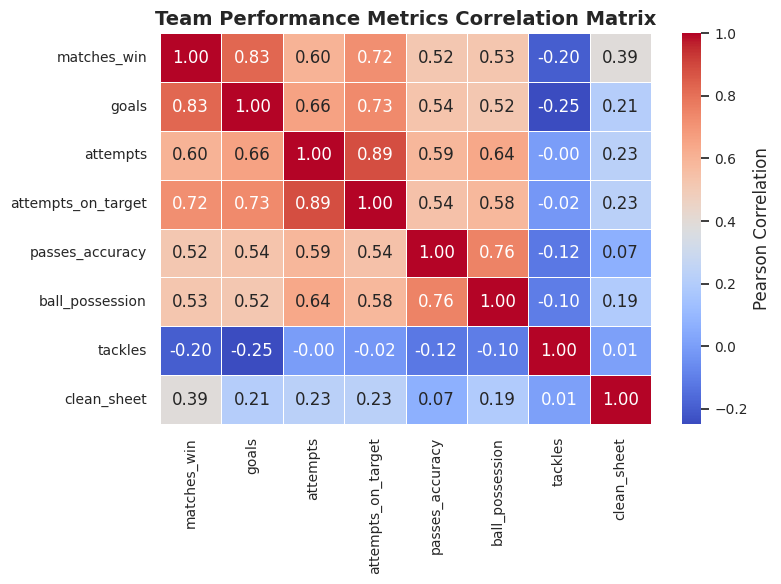

In [7]:
if 'teams_summary' in dfs:
    teams_df = dfs['teams_summary'].copy()
    
    # Select key numerical performance columns
    corr_cols = [
        'matches_win', 'goals', 'attempts', 'attempts_on_target', 
        'passes_accuracy', 'ball_possession', 'tackles', 'clean_sheet'
    ]
    available_corr = [c for c in corr_cols if c in teams_df.columns]
    
    plt.figure(figsize=(8, 6))
    corr_matrix = teams_df[available_corr].corr()
    
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, cbar_kws={'label': 'Pearson Correlation'})
    plt.title("Team Performance Metrics Correlation Matrix")
    plt.tight_layout()
    plt.show()

## 8: Top Scorers Bar Plot
Highlight the tournament's standout players using data from your player datasets (players_summary or players_latest).

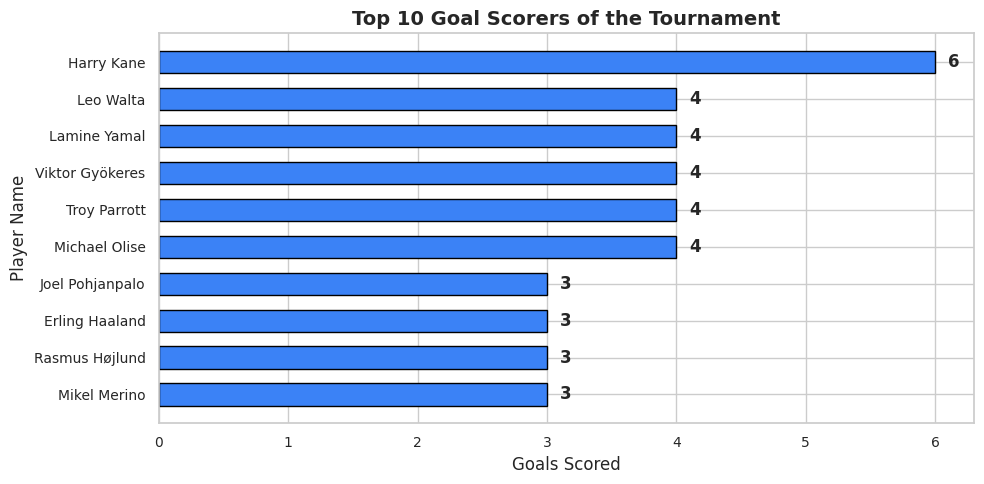

In [8]:
player_key = 'players_summary' if 'players_summary' in dfs else ('players_latest' if 'players_latest' in dfs else None)

if player_key and player_key in dfs:
    players_df = dfs[player_key].copy()
    
    # Check for goal columns
    goal_col = 'goals' if 'goals' in players_df.columns else [c for c in players_df.columns if 'goal' in c][0]
    name_col = 'player_name' if 'player_name' in players_df.columns else [c for c in players_df.columns if 'name' in c][0]
    
    top_scorers = players_df.sort_values(by=goal_col, ascending=False).head(10)
    
    plt.figure(figsize=(10, 5))
    bars = plt.barh(top_scorers[name_col][::-1], top_scorers[goal_col][::-1], color='#3b82f6', edgecolor='black', height=0.6)
    
    plt.title("Top 10 Goal Scorers of the Tournament")
    plt.xlabel("Goals Scored")
    plt.ylabel("Player Name")
    
    # Add values on bars
    for bar in bars:
        width = bar.get_width()
        plt.text(width + 0.1, bar.get_y() + bar.get_height()/2, f'{int(width)}', va='center', fontweight='bold')
        
    plt.tight_layout()
    plt.show()

## 9: Shooting Accuracy vs. Goals Scatter Plot
This visualization explores how efficiently teams convert their total shooting attempts into goals, helping distinguish clinical finishers from wasteful teams.

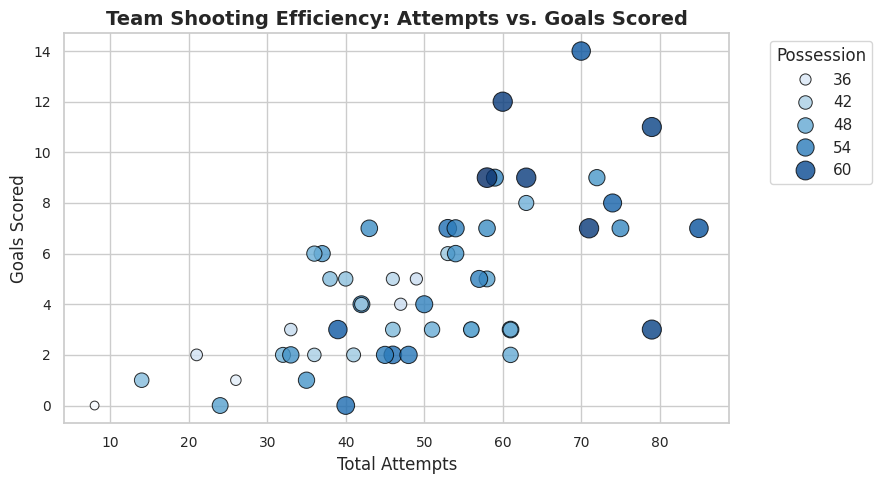

In [9]:
if 'teams_summary' in dfs:
    teams_df = dfs['teams_summary'].copy()
    
    if 'attempts' in teams_df.columns and 'goals' in teams_df.columns and 'team_name' in teams_df.columns:
        plt.figure(figsize=(9, 5))
        
        # Scatter plot
        sns.scatterplot(
            data=teams_df, x='attempts', y='goals', 
            size='ball_possession' if 'ball_possession' in teams_df.columns else None,
            hue='ball_possession' if 'ball_possession' in teams_df.columns else None,
            palette='Blues', sizes=(40, 200), alpha=0.8, edgecolor='black'
        )
        
        plt.title("Team Shooting Efficiency: Attempts vs. Goals Scored")
        plt.xlabel("Total Attempts")
        plt.ylabel("Goals Scored")
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Possession")
        plt.tight_layout()
        plt.show()

## 10: Disciplinary Breakdown (Yellow vs. Red Cards by Team)
Analyze team discipline by looking at the accumulation of yellow and red cards across the tournament.

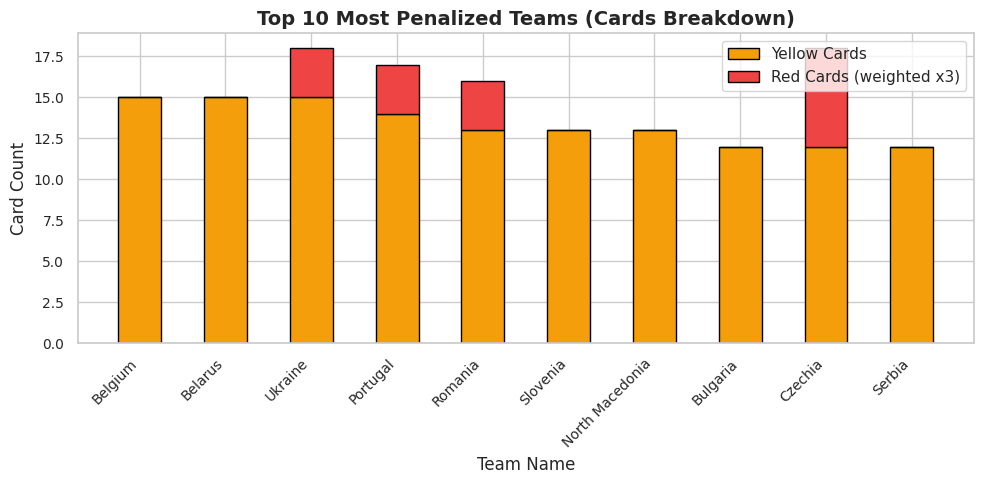

In [10]:
if 'teams_summary' in dfs:
    teams_df = dfs['teams_summary'].copy()
    
    if all(col in teams_df.columns for col in ['team_name', 'yellow_cards', 'red_cards']):
        # Top 10 most penalized teams based on yellow cards
        disciplined_df = teams_df.sort_values(by='yellow_cards', ascending=False).head(10)
        
        fig, ax = plt.subplots(figsize=(10, 5))
        
        ax.bar(disciplined_df['team_name'], disciplined_df['yellow_cards'], label='Yellow Cards', color='#f59e0b', width=0.5, edgecolor='black')
        ax.bar(disciplined_df['team_name'], disciplined_df['red_cards'] * 3, label='Red Cards (weighted x3)', color='#ef4444', width=0.5, bottom=disciplined_df['yellow_cards'], edgecolor='black')
        
        plt.title("Top 10 Most Penalized Teams (Cards Breakdown)")
        plt.xlabel("Team Name")
        plt.ylabel("Card Count")
        plt.xticks(rotation=45, ha='right')
        plt.legend()
        plt.tight_layout()
        plt.show()

## 11: Defensive Workload: Tackles vs. Clean Sheets
This scatter plot examines how defensive activity (tackles and clearance actions) correlates with keeping clean sheets across national teams.

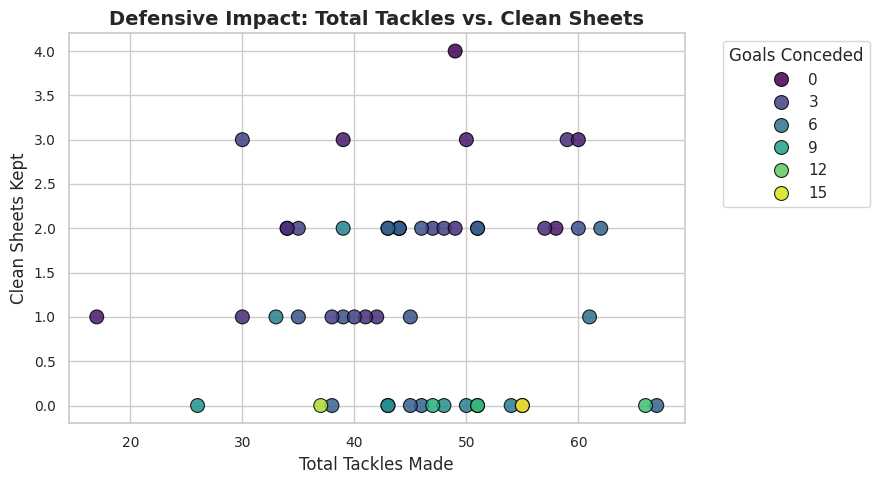

In [11]:
if 'teams_summary' in dfs:
    teams_df = dfs['teams_summary'].copy()
    
    if all(col in teams_df.columns for col in ['tackles', 'clean_sheet', 'team_name']):
        plt.figure(figsize=(9, 5))
        
        sns.scatterplot(
            data=teams_df, x='tackles', y='clean_sheet',
            hue='goals_conceded' if 'goals_conceded' in teams_df.columns else None,
            palette='viridis', s=100, edgecolor='black', alpha=0.85
        )
        
        plt.title("Defensive Impact: Total Tackles vs. Clean Sheets")
        plt.xlabel("Total Tackles Made")
        plt.ylabel("Clean Sheets Kept")
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Goals Conceded")
        plt.tight_layout()
        plt.show()

## 12: Positional Breakdown of Players in the Tournament
A horizontal bar chart showing the breakdown of player positions across all squads in the tournament dataset.

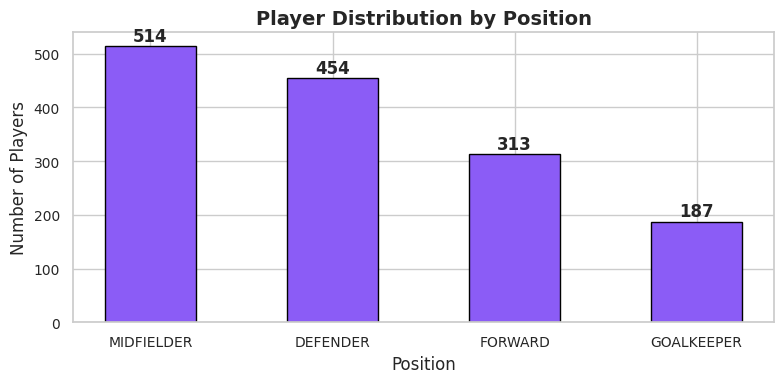

In [12]:
player_key = 'players_summary' if 'players_summary' in dfs else ('players_latest' if 'players_latest' in dfs else None)

if player_key and player_key in dfs:
    players_df = dfs[player_key].copy()
    
    pos_col = 'position' if 'position' in players_df.columns else [c for c in players_df.columns if 'pos' in c][0]
    
    if pos_col:
        pos_counts = players_df[pos_col].value_counts()
        
        plt.figure(figsize=(8, 4))
        bars = plt.bar(pos_counts.index, pos_counts.values, color='#8b5cf6', edgecolor='black', width=0.5)
        
        plt.title("Player Distribution by Position")
        plt.xlabel("Position")
        plt.ylabel("Number of Players")
        
        for bar in bars:
            height = bar.get_height()
            plt.text(bar.get_x() + bar.get_width()/2, height + 10, f'{int(height)}', ha='center', fontweight='bold')
            
        plt.tight_layout()
        plt.show()

## 13: Passing Accuracy vs. Passes Attempted (Passing Style Matrix)
This visualization helps identify teams that dominate possession through short passing volumes versus those playing a more direct game.

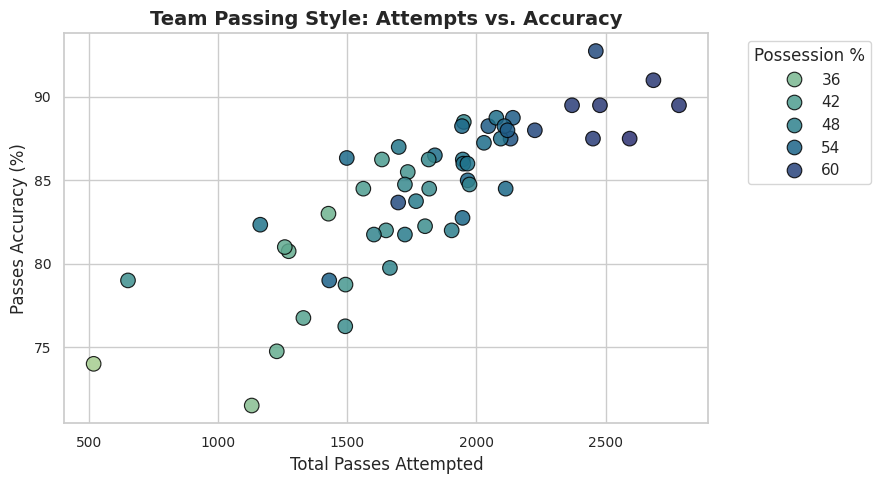

In [13]:
if 'teams_summary' in dfs:
    teams_df = dfs['teams_summary'].copy()
    
    if all(col in teams_df.columns for col in ['passes_attempted', 'passes_accuracy', 'team_name']):
        plt.figure(figsize=(9, 5))
        
        sns.scatterplot(
            data=teams_df, x='passes_attempted', y='passes_accuracy',
            hue='ball_possession' if 'ball_possession' in teams_df.columns else None,
            palette='crest', s=110, edgecolor='black', alpha=0.85
        )
        
        plt.title("Team Passing Style: Attempts vs. Accuracy")
        plt.xlabel("Total Passes Attempted")
        plt.ylabel("Passes Accuracy (%)")
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Possession %")
        plt.tight_layout()
        plt.show()

## 14: Fouls Committed vs. Fouls Suffered (Aggression Index)
This chart contrasts how aggressive teams are (fouls committed) relative to how heavily targeted they are by opponents (fouls suffered).

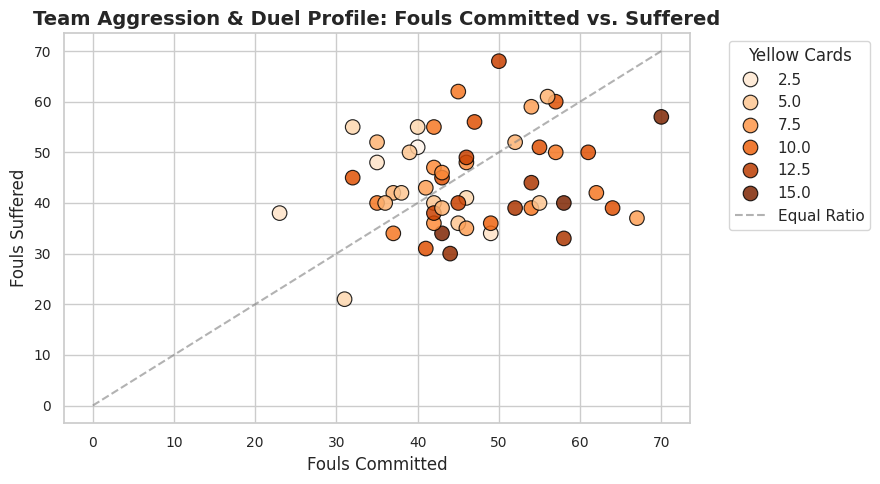

In [14]:
if 'teams_summary' in dfs:
    teams_df = dfs['teams_summary'].copy()
    
    if all(col in teams_df.columns for col in ['fouls_committed', 'fouls_suffered', 'team_name']):
        plt.figure(figsize=(9, 5))
        
        sns.scatterplot(
            data=teams_df, x='fouls_committed', y='fouls_suffered',
            hue='yellow_cards' if 'yellow_cards' in teams_df.columns else None,
            palette='Oranges', s=110, edgecolor='black', alpha=0.85
        )
        
        # Add a 45-degree reference line for equal fouls committed/suffered
        max_val = max(teams_df['fouls_committed'].max(), teams_df['fouls_suffered'].max())
        plt.plot([0, max_val], [0, max_val], color='gray', linestyle='--', alpha=0.6, label='Equal Ratio')
        
        plt.title("Team Aggression & Duel Profile: Fouls Committed vs. Suffered")
        plt.xlabel("Fouls Committed")
        plt.ylabel("Fouls Suffered")
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Yellow Cards")
        plt.tight_layout()
        plt.show()

## 15: Goal Timing and Efficiency: Inside vs. Outside Penalty Area
This cell calculates and visualizes how teams score their goals (inside the box vs. long-range strikes).

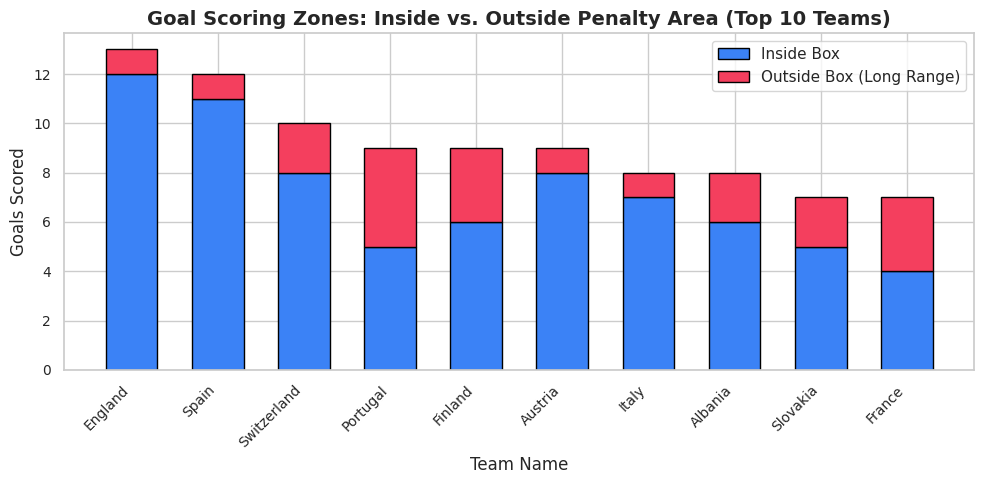

In [15]:
if 'teams_summary' in dfs:
    teams_df = dfs['teams_summary'].copy()
    
    if all(col in teams_df.columns for col in ['goals_scored_inside_penalty_area', 'goals_scored_outside_penalty_area', 'team_name']):
        # Sort by total goals and take top 10
        teams_df['total_scored'] = teams_df['goals_scored_inside_penalty_area'] + teams_df['goals_scored_outside_penalty_area']
        top_teams = teams_df.sort_values(by='total_scored', ascending=False).head(10)
        
        fig, ax = plt.subplots(figsize=(10, 5))
        
        ax.bar(top_teams['team_name'], top_teams['goals_scored_inside_penalty_area'], label='Inside Box', color='#3b82f6', width=0.6, edgecolor='black')
        ax.bar(top_teams['team_name'], top_teams['goals_scored_outside_penalty_area'], label='Outside Box (Long Range)', color='#f43f5e', width=0.6, bottom=top_teams['goals_scored_inside_penalty_area'], edgecolor='black')
        
        plt.title("Goal Scoring Zones: Inside vs. Outside Penalty Area (Top 10 Teams)")
        plt.xlabel("Team Name")
        plt.ylabel("Goals Scored")
        plt.xticks(rotation=45, ha='right')
        plt.legend()
        plt.tight_layout()
        plt.show()

## 16: Goalkeeping Performance: Saves vs. Clean Sheets
This cell analyzes defensive resistance by evaluating how goalkeeper saves correspond to clean sheets kept across national teams.

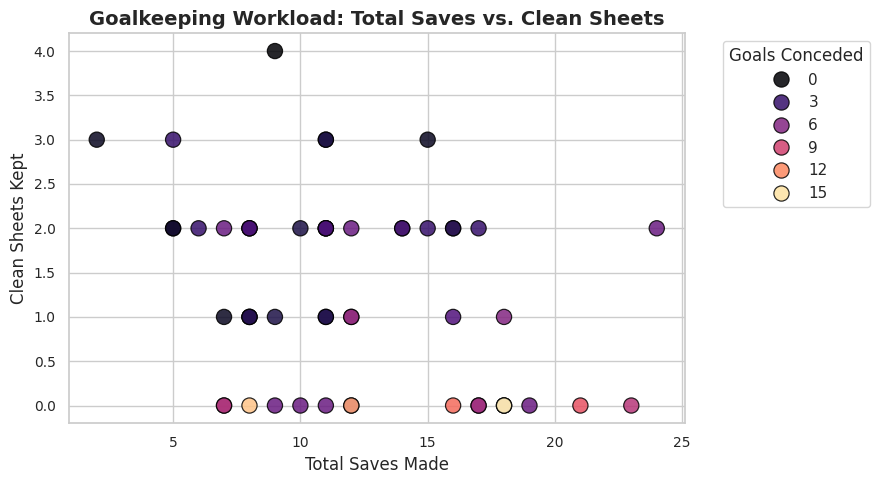

In [16]:
if 'teams_summary' in dfs:
    teams_df = dfs['teams_summary'].copy()
    
    if all(col in teams_df.columns for col in ['saves', 'clean_sheet', 'team_name']):
        plt.figure(figsize=(9, 5))
        
        sns.scatterplot(
            data=teams_df, x='saves', y='clean_sheet',
            hue='goals_conceded' if 'goals_conceded' in teams_df.columns else None,
            palette='magma', s=120, edgecolor='black', alpha=0.85
        )
        
        plt.title("Goalkeeping Workload: Total Saves vs. Clean Sheets")
        plt.xlabel("Total Saves Made")
        plt.ylabel("Clean Sheets Kept")
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Goals Conceded")
        plt.tight_layout()
        plt.show()

<div style="background: linear-gradient(135deg, #0b172a 0%, #1e293b 100%); border-radius: 12px; padding: 24px; color: white; text-align: center; margin-top: 32px;">
  <h2 style="color: #38bdf8; margin-bottom: 8px;">FULL TIME!</h2>
  <p style="color: #94a3b8; font-size: 14px; margin-bottom: 16px;">
    Thank you for exploring this UEFA Nations League analysis notebook. Feel free to fork, experiment, and upvote if you find it helpful!
  </p>
  <span style="background: #3b82f6; padding: 8px 16px; border-radius: 6px; font-weight: 600; font-size: 13px;">
    ⭐ Upvote on Kaggle to support!
  </span>
</div>